In [132]:
#Definicion de librerias

import qutip as qt
import numpy as np
import random
import matplotlib.pyplot as plt

%matplotlib inline
from IPython.display import Image
from qutip import *
from qutip_qip.operations import *
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator


In [133]:
#Definición de los dos estados de la base 
psi_0=qt.basis(2,0)
psi_1=qt.basis(2,1)


#Definicion del estado inicial como superposicion de los estados de la base
#coeficientes
a=1
b=1

psi_superposition=(a*psi_0+b*psi_1).unit()

psi_superposition

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.70710678]]

In [134]:
#Definicion de matrices de pauli

sigma_x=qt.sigmax()
sigma_y=qt.sigmay()
sigma_z=qt.sigmaz()

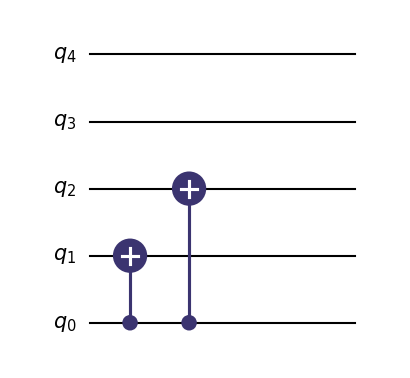

In [135]:
#Ejercicio 7

#Primero pasaramos del estado estado inicial en el sistema de 1 qubit a un sistema de tres qubits
#Para ello creamos un circuito de codificación de 3 qubits

#Partimos del producto del estado inicial con dos qubits en el estado 0
#Se añaden a su vez dos qubits ancilla que nos permitiran medir donde se encuentran los errores
q0=psi_superposition  # Estado |ψ>
q1=qt.basis(2, 0)  # Estado |0>
q_total = tensor(q0, q1, q1, q1, q1)

#Creamos un circuito de copiado del qubit inial en los otros dos
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc

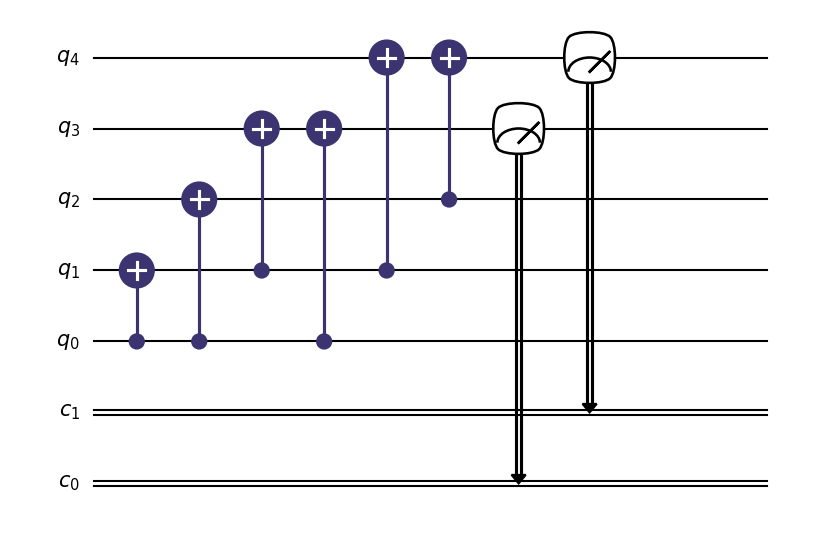

Sin error: ancilla 3 = 0, ancilla 4 = 0


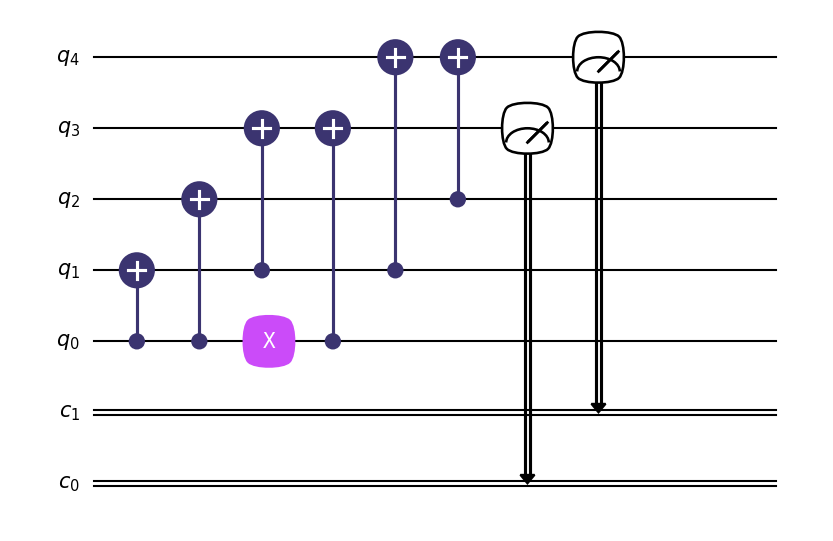

Error en el qubit 0: ancilla 3 = 1, ancilla 4 = 0


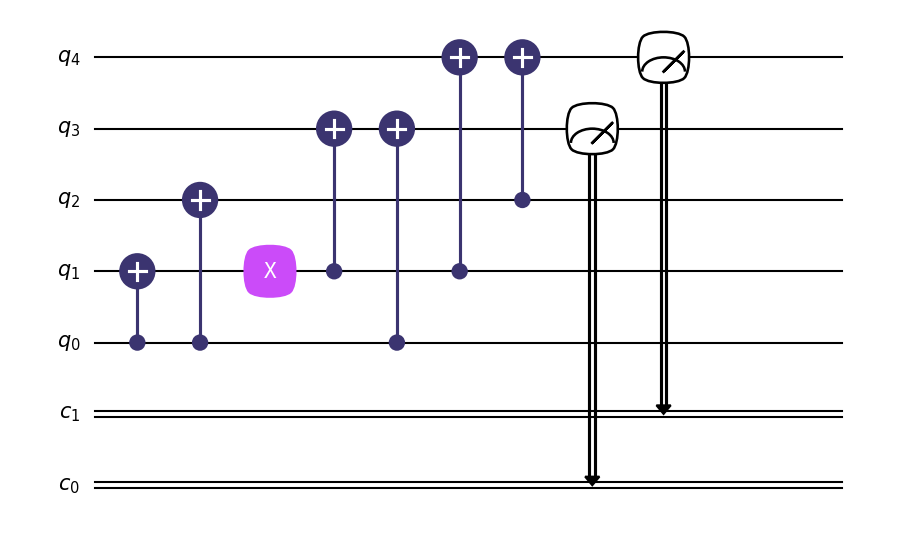

Error en el qubit 1: ancilla 3 = 1, ancilla 4 = 1


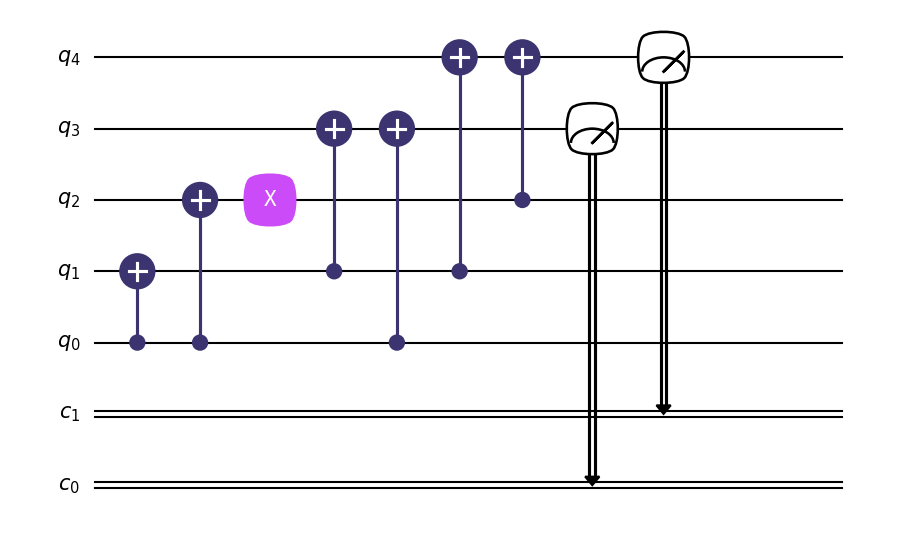

Error en el qubit 2: ancilla 3 = 0, ancilla 4 = 1


In [136]:
#Para comprobar si ha producido y donde se produce el error realizaremos dos metodos:
#Por un lado analizaremos el valor de los qubits ancillas implementados anteriormente

#Realizamos un bucle que nos recorra los 4 casos: No hay error, sí que lo hay en el qubit 1,2 o 3
for qubit_error in [None, 0, 1, 2]:

    qenc1=QubitCircuit(5, num_cbits=2, reverse_states=False)

    #Copiamos q0 en q1 y q2
    qenc1.add_gate("CNOT", controls=[0], targets=[1])
    qenc1.add_gate("CNOT", controls=[0], targets=[2])

    #Introducimos el error, excepto en el primer caso
    if qubit_error is not None:
        qenc1.add_gate("X", targets=[qubit_error])

    #Preparamos a las ancillas para ser medidas
    qenc1.add_gate("CNOT", controls=[1], targets=[3])
    qenc1.add_gate("CNOT", controls=[0], targets=[3])
    qenc1.add_gate("CNOT", controls=[1], targets=[4])
    qenc1.add_gate("CNOT", controls=[2], targets=[4])

    #Medimos las ancillas
    qenc1.add_measurement("M3", targets=[3], classical_store=0)
    qenc1.add_measurement("M4", targets=[4], classical_store=1)

    #Ejecutamos el circuito
    simulador=CircuitSimulator(qenc1)
    resultado=simulador.run(q_total, cbits=[0, 0])
    medidas = resultado.get_cbits(0)

    if qubit_error is None:
        nombre = "Sin error"

    else:
        nombre = f"Error en el qubit {qubit_error}"

    qenc1.draw("matplotlib")
    plt.show()


    print(f"{nombre}: ancilla 3 = {medidas[0]}, ancilla 4 = {medidas[1]}")

In [137]:
#Por otro lado estudiaremos el valor esperado de unos operadores de control

#Realizamos un bucle que nos recorra los 4 casos: No hay error, sí que lo hay en el qubit 1,2 o 3
for qubit_error in [None, 0, 1, 2]:

    qenc2=QubitCircuit(5, reverse_states=False)

    #Copiamos q0 en q1 y q2
    qenc2.add_gate("CNOT", controls=[0], targets=[1])
    qenc2.add_gate("CNOT", controls=[0], targets=[2])

    #Introducimos el error, excepto en el primer caso
    if qubit_error is not None:
        qenc2.add_gate("X", targets=[qubit_error])

    #Ejecutamos el circuito
    errorstate=qenc2.run(q_total)

    #Definimos los operadores de control para la corrección de errores
    op_Z1 = tensor(sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
    op_Z2 = tensor(qt.qeye(2), sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2))

    #Aplicamos los operadores de control al estado con error y calculamos los valores esperados
    val_ZZI = round(expect(op_Z1, errorstate))
    val_IZZ = round(expect(op_Z2, errorstate))

    if qubit_error is None:
        nombre = "Sin error"

    else:
        nombre = f"Error en el qubit {qubit_error}"

    print(f"{nombre}: <Z Z I>: {val_ZZI:.0f}, <I Z Z>: {val_IZZ:.0f}")

Sin error: <Z Z I>: 1, <I Z Z>: 1
Error en el qubit 0: <Z Z I>: -1, <I Z Z>: 1
Error en el qubit 1: <Z Z I>: -1, <I Z Z>: -1
Error en el qubit 2: <Z Z I>: 1, <I Z Z>: -1


In [138]:
#Por poner otro ejemplo, generaremos de forma aleatoria un flip-error en uno de los qubits y comprobaremos donde se ha producido de nuevo atraves de las ancillas y los operadores 
#Estado tras el copiado
U7=gate_sequence_product(qenc.propagators())
q_encoded7 = U7*q_total


#Introducimos un error de bit-flip en uno de los qubits
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()

errorstate = tensor(error_op) * q_encoded7
errorstate = errorstate.unit()
errorstate


Bit-flipping qubit 1


Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [139]:
#Preparamos a las ancillas para ser medidas
qenc3=QubitCircuit(5, num_cbits=2, reverse_states=False)

#Preparamos a las ancillas para ser medidas
qenc3.add_gate("CNOT", controls=[1], targets=[3])
qenc3.add_gate("CNOT", controls=[0], targets=[3])
qenc3.add_gate("CNOT", controls=[1], targets=[4])
qenc3.add_gate("CNOT", controls=[2], targets=[4])

#Medimos las ancillas
qenc3.add_measurement("M3", targets=[3], classical_store=0)
qenc3.add_measurement("M4", targets=[4], classical_store=1)

#Ejecutamos el circuito
simulador=CircuitSimulator(qenc3)
resultado=simulador.run(errorstate, cbits=[0, 0])
medidas = resultado.get_cbits(0)

print(f"ancilla 3 = {medidas[0]}")
print(f"ancilla 4 = {medidas[1]}")

if medidas[0] == 0 and medidas[1] == 0:
    print("No error detected.")
elif medidas[0] == 1 and medidas[1] == 0:
    print("Error detected on qubit 0.")
elif medidas[0] == 1 and medidas[1] == 1:
    print("Error detected on qubit 1.")
elif medidas[0] == 0 and medidas[1] == 1:
    print("Error detected on qubit 2.")

ancilla 3 = 1
ancilla 4 = 1
Error detected on qubit 1.


In [140]:
#Comprobamos con los operadores de control
op_Z1 = tensor(sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
op_Z2 = tensor(qt.qeye(2), sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2))

val_ZZI = round(expect(op_Z1, errorstate))
val_IZZ = round(expect(op_Z2, errorstate))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("No error detected.")
elif val_ZZI == -1 and val_IZZ == 1:
    print("Error detected on qubit 0.")
elif val_ZZI == 1 and val_IZZ == -1:
    print("Error detected on qubit 2.")
elif val_ZZI == -1 and val_IZZ == -1:
    print("Error detected on qubit 1.")

 <Z Z I>: -1
 <I Z Z>: -1
Error detected on qubit 1.


Bit-flipping qubit 2


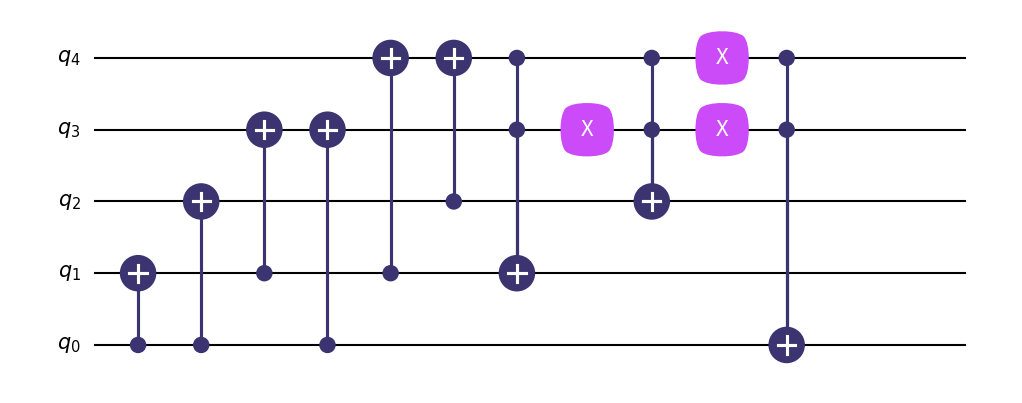

In [141]:
#Ejercicio 8
#circuito
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()
qenc.add_gate("CNOT", controls=[1], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[1], targets=[4])
qenc.add_gate("CNOT", controls=[2], targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[1])
qenc.add_gate("X", targets=[3])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[2])
qenc.add_gate("X", targets=[3])
qenc.add_gate("X", targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[0])
qenc

In [142]:
#ejercicio 8
#implementación del circuito de corrección de errores sobre chi 
U8=gate_sequence_product(qenc.propagators())
q_encoded8=U8*q_total

#comprobación de si se ha corregido el error
val_ZZI = round(expect(op_Z1, q_encoded8))
val_IZZ = round(expect(op_Z2, q_encoded8))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("se ha corregido el error.")
else:
    print("no se ha corregido el error.")

 <Z Z I>: 1
 <I Z Z>: 1
se ha corregido el error.


In [143]:
#Ejercicio 9
#Definimos el estado inicial de 9 qubits 
q9=qt.tensor(psi_superposition,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0)


#Mostramos este estado por pantalla(solo los valore distintos de 0) 
coeficientes = q9.full().ravel()

for i, coef in enumerate(coeficientes):
    if abs(coef) > 1e-10:
        print(f"|{i:09b}>: {coef:.6g}")

|000000000>: 0.707107+0j
|100000000>: 0.707107+0j


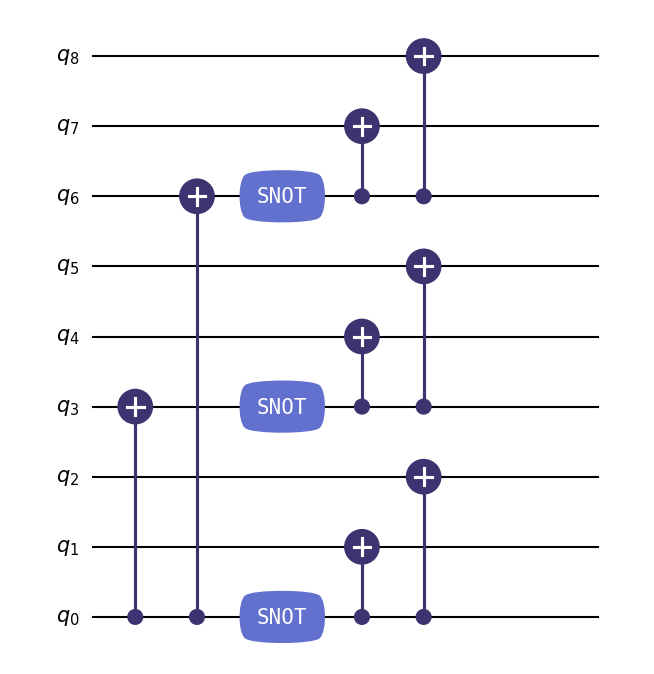

In [144]:
#Creamos el circuito que representa la parte de copiada en la base |+> |->
qenc = QubitCircuit(9, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[6])
qenc.add_gate("SNOT", targets=[0])
qenc.add_gate("SNOT", targets=[3])
qenc.add_gate("SNOT", targets=[6])
qenc.add_gate("CNOT", controls=[6], targets=[7])
qenc.add_gate("CNOT", controls=[6], targets=[8])
qenc.add_gate("CNOT", controls=[3], targets=[4])
qenc.add_gate("CNOT", controls=[3], targets=[5])
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc

In [145]:
#Veamos ahora cual es el estado final en el sistema de 9-qubits tras hacer atravesar el estado inicial por el circuito cuantico

result= qenc.run(q9)

#Mostramos el estado resultante

coeficientes = result.full().ravel()

for i, coef in enumerate(coeficientes):
    if abs(coef) > 1e-10:
        print(f"|{i:09b}>: {coef:.6g}")



|000000000>: 0.5+0j
|000111111>: 0.5+0j
|111000111>: 0.5+0j
|111111000>: 0.5+0j


In [146]:
#Realizamos un bucle que nos recorra los 9 casos: Los posibles errores de cambio de fase en cada uno de los qubits
estados=[]
for qubit_error in range(9):

    qenc=QubitCircuit(9, reverse_states=False)

    #Proceso de copiado
    qenc.add_gate("CNOT", controls=[0], targets=[3])
    qenc.add_gate("CNOT", controls=[0], targets=[6])
    qenc.add_gate("SNOT", targets=[0])
    qenc.add_gate("SNOT", targets=[3])
    qenc.add_gate("SNOT", targets=[6])
    qenc.add_gate("CNOT", controls=[6], targets=[7])
    qenc.add_gate("CNOT", controls=[6], targets=[8])
    qenc.add_gate("CNOT", controls=[3], targets=[4])
    qenc.add_gate("CNOT", controls=[3], targets=[5])
    qenc.add_gate("CNOT", controls=[0], targets=[1])
    qenc.add_gate("CNOT", controls=[0], targets=[2])

    #Introducimos el error
    qenc.add_gate("Z", targets=[qubit_error])

    #Ejecutamos el circuito y guardamos el estado resultante en el array de estados
    estados.append(qenc.run(q9))

In [147]:
#Comparemos ahora si los estados obtenidos son iguales dentro de un mismo bloque y diferentes para diferentes bloques
#Definimos ahora un valor de tolerancia muy pequeño para cuando la norma entre dos estados es 0 y por tanto son iguales
tolerancia = 1e-10

# Comprobamos primero que el estado resultante cuando el error se produce en el mismo bloque es igual
# Bloques: (0, 1, 2), (3, 4, 5) y (6, 7, 8)
for bloque in range(3):
    iguales=True
    inicio = 3 * bloque

    for i in range (inicio, inicio +3):
        for j in range (i+1,inicio+3):
            if((estados[i] - estados[j]).norm() > tolerancia):
                iguales=False
    
    print(f"Bloque {bloque + 1}: todos los estados son iguales → {iguales}")

# Ahora comparamos todas las posibles parejas de estados de qubits en distintos bloques y vemos que son diferentes 
diferentes = True

for i in range(9):
    for j in range(i + 1, 9):
        if i // 3 != j // 3:  # Los qubits pertenecen a bloques distintos
            distancia = (estados[i] - estados[j]).norm()

            if distancia <= tolerancia:
                diferentes = False
                print(f"Los errores Z en los qubits {i} y {j} dan el mismo estado.")

print(f"Errores en bloques distintos: estados diferentes → {diferentes}")

Bloque 1: todos los estados son iguales → True
Bloque 2: todos los estados son iguales → True
Bloque 3: todos los estados son iguales → True
Errores en bloques distintos: estados diferentes → True


|000000000>: 0.707107+0j
|100000000>: 0.707107+0j


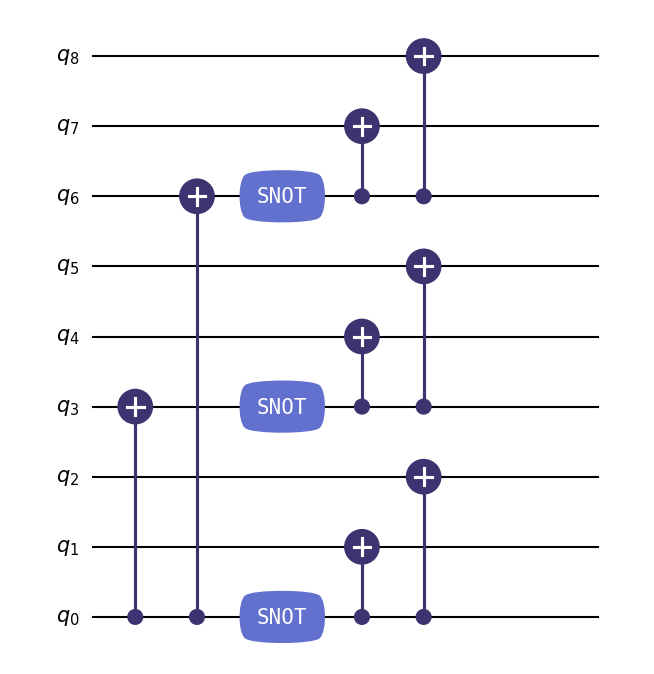

In [148]:
#Ejercicio 10
#operadores O1 y O2 de control para detección de flip de fase (9 qubits)
psi_1=qt.tensor(psi_superposition,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0)


#Mostramos este estado por pantalla 
coeficientes = psi_1.full().ravel()

for i, coef in enumerate(coeficientes):
    if abs(coef) > 1e-10:
        print(f"|{i:09b}>: {coef:.6g}")

qenc = QubitCircuit(9, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[6])
qenc.add_gate("SNOT", targets=[0])
qenc.add_gate("SNOT", targets=[3])
qenc.add_gate("SNOT", targets=[6])
qenc.add_gate("CNOT", controls=[6], targets=[7])
qenc.add_gate("CNOT", controls=[6], targets=[8])
qenc.add_gate("CNOT", controls=[3], targets=[4])
qenc.add_gate("CNOT", controls=[3], targets=[5])
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
U10=gate_sequence_product(qenc.propagators())
qenc

In [149]:
#introducimos un error de flip de fase en uno de los qubits

error_op = [qeye(2)]*9
phase_qubit = random.randint(0, 8) # qubit to phase-
print("Phase-flippping qubit {}".format(phase_qubit))
error_op[phase_qubit] *= sigmaz()

q_encoded10 = tensor(error_op) * U10*psi_1

#q_encoded10 = U10 * psi_1

# 2. Definir una lista de 9 identidades
#error_op = [qt.qeye(2)] * 9

# 3. Colocar el error en el cúbit
#error_op[8] = qt.sigmaz()  # o qt.sigmaz() para error de fase

# 4. Aplicar el producto tensor al estado
#q_encoded10 = qt.tensor(error_op) * q_encoded10

Phase-flippping qubit 5


In [150]:
O1=tensor(sigmax(), sigmax(), sigmax(), sigmax(),sigmax(), sigmax(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
O2=tensor(qt.qeye(2), qt.qeye(2), qt.qeye(2), sigmax(), sigmax(), sigmax(), sigmax(), sigmax(), sigmax())


#aplicamos los operadores de control al estado con error y calculamos los valores esperados

val_O1 = round(expect(O1, q_encoded10))
val_O2 = round(expect(O2, q_encoded10))

print(f" <O1>: {val_O1:.0f}")
print(f" <O2>: {val_O2:.0f}")
if val_O1 == 1 and val_O2 == 1:
    print("No error detected.")
elif val_O1 == -1 and val_O2 == 1:
    print("Error detected on block 0.")
elif val_O1 == 1 and val_O2 == -1:
    print("Error detected on block 2.")
elif val_O1 == -1 and val_O2 == -1:
    print("Error detected on block 1.")

 <O1>: -1
 <O2>: -1
Error detected on block 1.


In [151]:
#arreglar el error de flip de fase
error_correccion= [qeye(2)]*9
error_correccion[phase_qubit] *= sigmaz()
q_encoded10 = tensor(error_correccion) * q_encoded10
val_O1 = round(expect(O1, q_encoded10))
val_O2 = round(expect(O2, q_encoded10))

print(f" <O1>: {val_O1:.0f}")
print(f" <O2>: {val_O2:.0f}")
if val_O1 == 1 and val_O2 == 1:
    print("No error detected.")
elif val_O1 == -1 and val_O2 == 1:
    print("Error detected on block 0.")
elif val_O1 == 1 and val_O2 == -1:
    print("Error detected on block 2.")
elif val_O1 == -1 and val_O2 == -1:
    print("Error detected on block 1.")

 <O1>: 1
 <O2>: 1
No error detected.
